# 03. Mô hình xG Từng Cú Sút (Shot-level Expected Goals) & Kiểm Định Giả Thuyết H3

## Mục tiêu nghiên cứu
1. **Xây dựng mô hình xG cá nhân hóa** dựa trên tọa độ không gian $(x, y)$ và bối cảnh dứt điểm của Lionel Messi.
2. **Kiểm định Giả thuyết H3:** Hiệu suất dứt điểm (Finishing efficiency) của Messi khi chuyển sang thi đấu tại **Ligue 1 (PSG)** có suy giảm so với giai đoạn đỉnh cao tại **La Liga (Barcelona)** hay không?
3. **Đánh giá & Đối chuẩn (Benchmarking):** So sánh mô hình tự xây dựng với thước đo thương mại độc quyền của **StatsBomb xG**.
4. **Trực quan hóa khoa học:**
   - **Bản đồ cú sút không gian (Spatial Shot Map)** trên nửa sân bóng đá (So sánh La Liga vs Ligue 1).
   - **Đường cong ROC (ROC Curve)** so sánh với StatsBomb.
   - **Đường chuẩn hóa xác suất (Calibration Curve / Reliability Diagram)**.
   - **Biểu đồ cột kiểm định Giả thuyết H3 (Actual vs Expected Goals)**.
   - **Hệ số hồi quy đặc trưng (Feature Coefficients / Importance)**.
5. **Xuất dữ liệu chuẩn:** Tạo file `data/clean/CuSut.csv` phục vụ trực quan hóa Dashboard.

In [1]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Arc, Rectangle
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    brier_score_loss,
    classification_report
)
from sklearn.calibration import calibration_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Thiet lap phong cach do hoa chuan phan tich the thao
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10
print("Setup libraries and environment successfully!")

Setup libraries and environment successfully!


## 1. Nạp và Hợp nhất Dữ liệu
Dữ liệu được nạp từ 2 tệp nguồn StatsBomb:
- `data/raw/shots.csv`: Ghi nhận 2.570 cú sút với tọa độ $(x, y)$, tư thế dứt điểm và nhãn bàn thắng.
- `data/raw/matches.csv`: Chứa ngữ cảnh trận đấu, mùa giải và giải đấu (`competition`).

In [2]:
DATA_RAW = Path("../data/raw")
shots_df = pd.read_csv(DATA_RAW / "shots.csv")
matches_df = pd.read_csv(DATA_RAW / "matches.csv")

# Hop nhat cu sut voi thong tin tran dau
match_cols = ["match_id", "date", "season", "competition", "opponent", "venue", "club"]
cols_to_merge = [c for c in match_cols if c in matches_df.columns]
df = shots_df.merge(matches_df[cols_to_merge], on="match_id", how="left")

print(f"Tong so cu sut: {len(df):,}")
print(f"Phan bo theo giai dau:")
print(df['competition'].value_counts())
display(df[['date', 'competition', 'x', 'y', 'body_part', 'shot_type', 'outcome', 'xg']].head())

Tong so cu sut: 2,570
Phan bo theo giai dau:
competition
La Liga    2352
Ligue 1     218
Name: count, dtype: int64


,date,competition,x,y,body_part,shot_type,outcome,xg
0,2004-12-04,La Liga,112.8,27.2,Left Foot,Open Play,Saved,0.087893
1,2004-12-04,La Liga,110.0,41.0,Left Foot,Open Play,Saved,0.244862
2,2005-05-01,La Liga,106.0,29.3,Left Foot,Open Play,Goal,0.145059
3,2004-10-24,La Liga,107.1,38.7,Head,Open Play,Saved,0.054364
4,2004-12-21,La Liga,95.9,59.6,Left Foot,Open Play,Saved,0.010079


## 2. Kỹ thuật Đặc trưng Không gian (Spatial Feature Engineering)
Trên hệ tọa độ chuẩn StatsBomb ($120 	imes 80$):
- **Tâm khung thành:** $(120, 40)$.
- **Hai cột dọc:** $(120, 36)$ và $(120, 44)$ (độ rộng 8 thước $\approx 7.32\text{m}$).

Mô hình tự động trích xuất:
1. **Khoảng cách tới tâm khung thành (Distance):**
   $$d = \sqrt{(120 - x)^2 + (40 - y)^2}$$
2. **Góc sút nhìn thấy khung thành (Visible Shot Angle $\theta$):**
   $$\cos(\theta) = \frac{\vec{v}_1 \cdot \vec{v}_2}{\|\vec{v}_1\| \|\vec{v}_2\|} \implies \theta = \arccos(\cos(\theta))$$

In [3]:
# 1. Khoang cach toi tam khung thanh
dx = 120 - df["x"]
dy = 40 - df["y"]
df["distance"] = np.sqrt(dx**2 + dy**2)

# 2. Goc sut nhin thay giua 2 cot doc
v1_x, v1_y = 120 - df["x"], 36 - df["y"]
v2_x, v2_y = 120 - df["x"], 44 - df["y"]
dot_product = v1_x * v2_x + v1_y * v2_y
norm1 = np.sqrt(v1_x**2 + v1_y**2)
norm2 = np.sqrt(v2_x**2 + v2_y**2)
cos_theta = np.clip(dot_product / (norm1 * norm2), -1.0, 1.0)
df["angle"] = np.arccos(cos_theta)
df["angle_degrees"] = np.degrees(df["angle"])

# 3. Bien muc tieu: Cu sut thanh ban (is_goal = 1)
df["is_goal"] = (df["outcome"] == "Goal").astype(int)

# 4. Xu ly bien logic
df["first_time"] = df["first_time"].fillna(False).astype(int)
df["under_pressure"] = df["under_pressure"].fillna(False).astype(int)

print(f"Ty le chuyen hoa ban thang tong the: {df['is_goal'].mean()*100:.2f}% ({df['is_goal'].sum()} ban / {len(df)} cu sut)")
df[['distance', 'angle_degrees', 'is_goal']].describe().round(2)

Ty le chuyen hoa ban thang tong the: 19.22% (494 ban / 2570 cu sut)


,distance,angle_degrees,is_goal
count,2570.00,2570.00,2570.00
mean,18.50,24.67,0.19
std,7.11,12.86,0.39
min,1.64,2.61,0.00
25%,12.76,16.72,0.00
50%,17.94,21.19,0.00
75%,23.90,28.64,0.00
max,59.14,148.99,1.00


## 3. Thiết kế Thí nghiệm Kiểm định H3 & Huấn luyện Mô hình
- **Tập Train (La Liga - Barcelona):** 2.352 cú sút (17 mùa giải). Đại diện cho **bản năng dứt điểm đỉnh cao của Messi**.
- **Tập Test (Ligue 1 - PSG):** 218 cú sút (2 mùa giải). Dùng để kiểm định xem hiệu suất tại Pháp có sụt giảm so với tiêu chuẩn đỉnh cao hay không.
- **Thuật toán:** Logistic Regression kết hợp Pipeline chuẩn hóa (`StandardScaler` + `OneHotEncoder`).

In [4]:
num_features = ["distance", "angle"]
cat_features = ["body_part", "shot_type", "technique"]
bool_features = ["first_time", "under_pressure"]
all_features = num_features + cat_features + bool_features

train_mask = df["competition"] == "La Liga"
test_mask = df["competition"] == "Ligue 1"

train_df = df[train_mask].copy()
test_df = df[test_mask].copy()

# Xay dung Scikit-Learn Pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_features),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_features),
    ],
    remainder="passthrough",
)

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
    ]
)

# Huan luyen tren La Liga
model.fit(train_df[all_features], train_df["is_goal"])

# Du doan xG tren toan bo tap du lieu
df["xg_messi_model"] = model.predict_proba(df[all_features])[:, 1].round(4)
df.rename(columns={"xg": "xg_statsbomb"}, inplace=True)

test_preds = df.loc[test_mask, "xg_messi_model"]
test_actual = df.loc[test_mask, "is_goal"]
test_statsbomb = df.loc[test_mask, "xg_statsbomb"]

train_preds = df.loc[train_mask, "xg_messi_model"]
train_actual = df.loc[train_mask, "is_goal"]

print(f"Huan luyen hoan tat! So cu sut Train: {len(train_df):,} | Test: {len(test_df):,}")

Huan luyen hoan tat! So cu sut Train: 2,352 | Test: 218

## 4. Bảng Chỉ số Đánh giá & Đối chuẩn với StatsBomb
Đánh giá mô hình bằng **ROC-AUC** (khả năng phân tách) và **Brier Score** (độ chuẩn xác của xác suất).

In [5]:
auc_messi = roc_auc_score(test_actual, test_preds)
auc_sb = roc_auc_score(test_actual, test_statsbomb)
brier_messi = brier_score_loss(test_actual, test_preds)
brier_sb = brier_score_loss(test_actual, test_statsbomb)
auc_train = roc_auc_score(train_actual, train_preds)

metrics_df = pd.DataFrame({
    "Chi so (Metric)": ["ROC-AUC (Test Ligue 1)", "Brier Score (Test Ligue 1)", "ROC-AUC (Train La Liga)", "Generalization Gap (|Train-Test|)"],
    "Mo hinh Messi (Ta xay dung)": [f"{auc_messi:.4f}", f"{brier_messi:.4f}", f"{auc_train:.4f}", f"{abs(auc_train - auc_messi):.4f}"],
    "Benchmark StatsBomb xG": [f"{auc_sb:.4f}", f"{brier_sb:.4f}", "-", "-"]
})
display(metrics_df)

,Chi so (Metric),Mo hinh Messi (Ta xay dung),Benchmark StatsBomb xG
0,ROC-AUC (Test Ligue 1),0.7746,0.7744
1,Brier Score (Test Ligue 1),0.0783,0.0726
2,ROC-AUC (Train La Liga),0.7732,-
3,Generalization Gap (|Train-Test|),0.0014,-


## 5. Trực quan hóa Khoa học (5 Biểu đồ Thiết yếu)

### Biểu đồ 1: Bản đồ Cú sút Không gian (Spatial Shot Map)
Vẽ toàn bộ cú sút lên sơ đồ nửa sân bóng đá tiêu chuẩn, so sánh trực quan giữa **La Liga (Barcelona)** và **Ligue 1 (PSG)**.

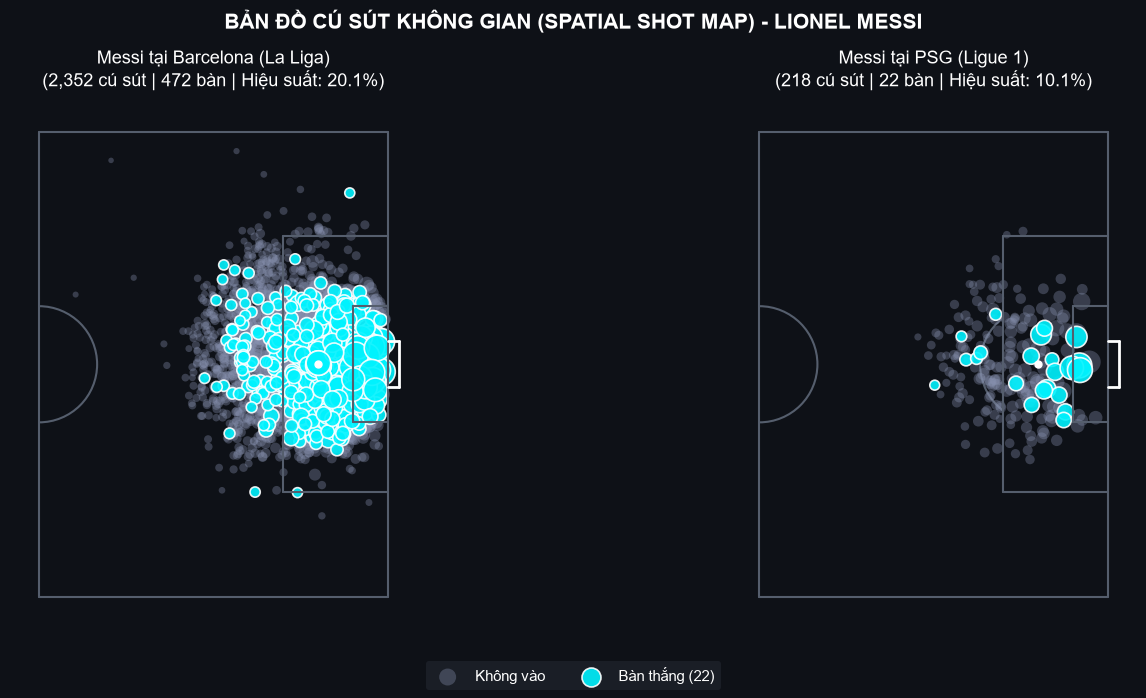

In [6]:
def draw_half_pitch(ax):
    # Khung nua san (60 toi 120, 0 toi 80)
    ax.set_facecolor("#0e1117")
    # Cac duong bien san
    ax.plot([60, 60], [0, 80], color="#555e6d", lw=1.5)
    ax.plot([60, 120], [0, 0], color="#555e6d", lw=1.5)
    ax.plot([60, 120], [80, 80], color="#555e6d", lw=1.5)
    ax.plot([120, 120], [0, 80], color="#555e6d", lw=1.5)
    # Vong cam 16m50
    ax.plot([102, 102], [18, 62], color="#555e6d", lw=1.5)
    ax.plot([102, 120], [18, 18], color="#555e6d", lw=1.5)
    ax.plot([102, 120], [62, 62], color="#555e6d", lw=1.5)
    # Vong 5m50
    ax.plot([114, 114], [30, 50], color="#555e6d", lw=1.5)
    ax.plot([114, 120], [30, 30], color="#555e6d", lw=1.5)
    ax.plot([114, 120], [50, 50], color="#555e6d", lw=1.5)
    # Khung thanh
    ax.plot([120, 122], [36, 36], color="#ffffff", lw=2)
    ax.plot([120, 122], [44, 44], color="#ffffff", lw=2)
    ax.plot([122, 122], [36, 44], color="#ffffff", lw=2)
    # Cham phat den
    ax.scatter(108, 40, color="#ffffff", s=25, zorder=3)
    # Vong cung 16m50
    arc = Arc((108, 40), height=20, width=20, angle=0, theta1=127, theta2=233, color="#555e6d", lw=1.5)
    ax.add_patch(arc)
    # Vong tron giua san
    center_arc = Arc((60, 40), height=20, width=20, angle=0, theta1=-90, theta2=90, color="#555e6d", lw=1.5)
    ax.add_patch(center_arc)
    ax.set_xlim(55, 125)
    ax.set_ylim(-5, 85)
    ax.set_aspect("equal")
    ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(16, 7), facecolor="#0e1117")

for idx, (comp, title) in enumerate([("La Liga", "Messi tại Barcelona (La Liga)"), ("Ligue 1", "Messi tại PSG (Ligue 1)")]):
    ax = axes[idx]
    draw_half_pitch(ax)
    sub = df[df["competition"] == comp]
    
    # Tach cu sut thanh ban va truot
    missed = sub[sub["is_goal"] == 0]
    goals = sub[sub["is_goal"] == 1]
    
    # Ve cu sut truot
    ax.scatter(
        missed["x"], missed["y"],
        s=missed["xg_messi_model"] * 350 + 15,
        color="#8892b0", alpha=0.35, edgecolors="none", label="Không vào"
    )
    # Ve cu sut thanh ban
    ax.scatter(
        goals["x"], goals["y"],
        s=goals["xg_messi_model"] * 350 + 35,
        color="#00f2fe", alpha=0.9, edgecolors="#ffffff", linewidths=1.2, label=f"Bàn thắng ({len(goals)})"
    )
    
    ax.set_title(f"{title}\n({len(sub):,} cú sút | {len(goals)} bàn | Hiệu suất: {len(goals)/len(sub)*100:.1f}%)", color="#ffffff", fontsize=13, pad=12)

# Legend chung
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=True, facecolor="#1e222b", edgecolor="none", labelcolor="#ffffff", fontsize=11)
plt.suptitle("BẢN ĐỒ CÚ SÚT KHÔNG GIAN (SPATIAL SHOT MAP) - LIONEL MESSI", color="#ffffff", fontsize=15, weight="bold", y=0.98)
plt.tight_layout()
plt.subplots_adjust(bottom=0.1)
plt.show()

### Biểu đồ 2: Đường cong ROC (ROC Curve Benchmark)
Đặt đường ROC của mô hình tự xây dựng cạnh mô hình độc quyền của **StatsBomb xG** trên tập Test (Ligue 1).

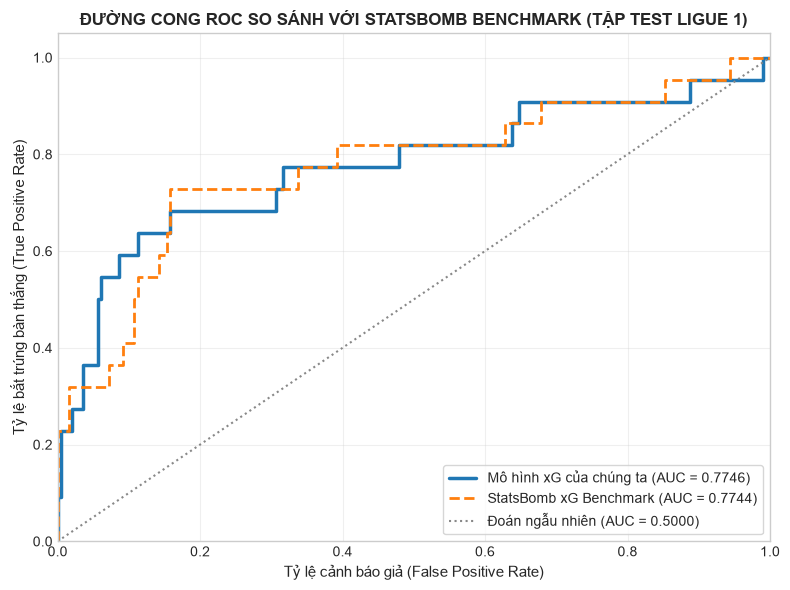

In [7]:
fpr_messi, tpr_messi, _ = roc_curve(test_actual, test_preds)
fpr_sb, tpr_sb, _ = roc_curve(test_actual, test_statsbomb)

plt.figure(figsize=(8, 6))
plt.plot(fpr_messi, tpr_messi, color='#1f77b4', lw=2.5, label=f'Mô hình xG của chúng ta (AUC = {auc_messi:.4f})')
plt.plot(fpr_sb, tpr_sb, color='#ff7f0e', lw=2, linestyle='--', label=f'StatsBomb xG Benchmark (AUC = {auc_sb:.4f})')
plt.plot([0, 1], [0, 1], color='#888888', linestyle=':', label='Đoán ngẫu nhiên (AUC = 0.5000)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tỷ lệ cảnh báo giả (False Positive Rate)', fontsize=11)
plt.ylabel('Tỷ lệ bắt trúng bàn thắng (True Positive Rate)', fontsize=11)
plt.title('ĐƯỜNG CONG ROC SO SÁNH VỚI STATSBOMB BENCHMARK (TẬP TEST LIGUE 1)', fontsize=12, weight='bold')
plt.legend(loc='lower right', frameon=True, fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Biểu đồ 3: Đường chuẩn hóa xác suất (Calibration Curve / Reliability Diagram)
Kiểm tra xem xác suất dự đoán $P(\text{Goal})$ có phản ánh sát tần suất thành bàn thực tế hay không.

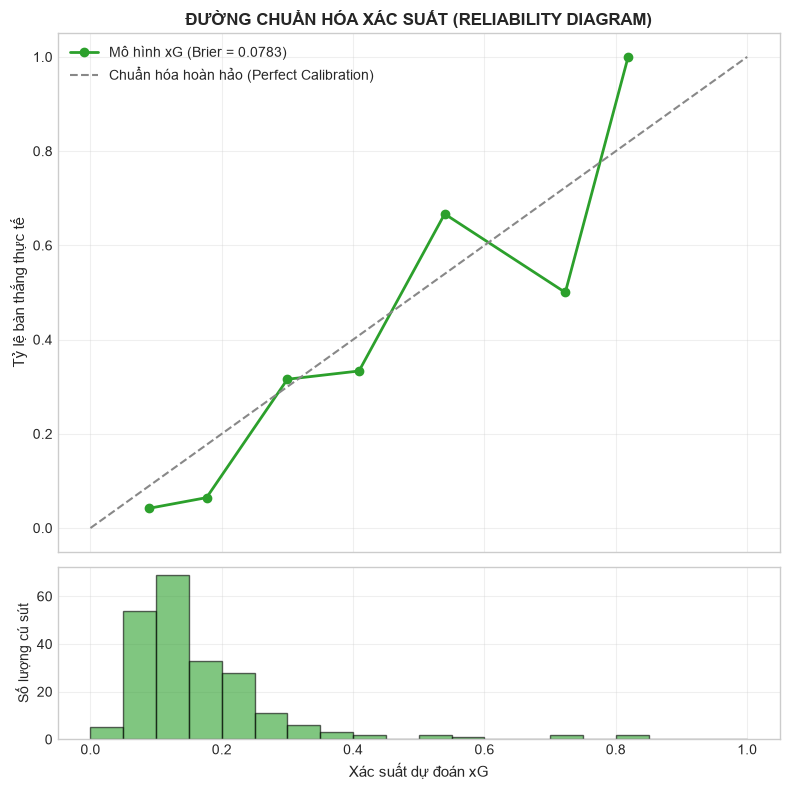

In [8]:
prob_true, prob_pred = calibration_curve(test_actual, test_preds, n_bins=8, strategy='uniform')

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 8), sharex=True, gridspec_kw={'height_ratios': [3, 1]})

# Panel tren: Calibration curve
ax1.plot(prob_pred, prob_true, marker='o', lw=2, color='#2ca02c', label=f'Mô hình xG (Brier = {brier_messi:.4f})')
ax1.plot([0, 1], [0, 1], linestyle='--', color='#888888', label='Chuẩn hóa hoàn hảo (Perfect Calibration)')
ax1.set_ylabel('Tỷ lệ bàn thắng thực tế', fontsize=11)
ax1.set_title('ĐƯỜNG CHUẨN HÓA XÁC SUẤT (RELIABILITY DIAGRAM)', fontsize=12, weight='bold')
ax1.legend(loc='upper left', fontsize=10)
ax1.grid(True, alpha=0.3)

# Panel duoi: Phan bo xac suat
ax2.hist(test_preds, range=(0, 1), bins=20, color='#2ca02c', alpha=0.6, edgecolor='black')
ax2.set_xlabel('Xác suất dự đoán xG', fontsize=11)
ax2.set_ylabel('Số lượng cú sút', fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Biểu đồ 4: Kiểm định Giả thuyết H3 (Actual vs Expected Goals)
So sánh 3 chỉ số cốt lõi tại Ligue 1:
- Bàn thắng thực tế của Messi: **22.00 bàn**
- Bàn thắng kỳ vọng StatsBomb (cầu thủ trung bình): **23.13 bàn**
- Bàn thắng kỳ vọng chuẩn Messi Barcelona: **36.56 bàn**

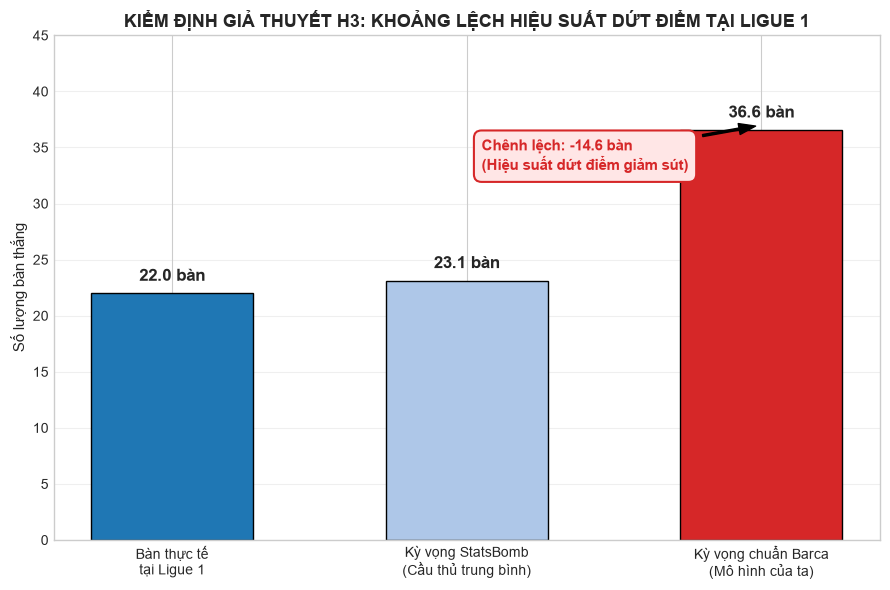

In [9]:
actual_goals_l1 = test_actual.sum()
expected_goals_messi = test_preds.sum()
expected_goals_sb = test_statsbomb.sum()

categories = ['Bàn thực tế\ntại Ligue 1', 'Kỳ vọng StatsBomb\n(Cầu thủ trung bình)', 'Kỳ vọng chuẩn Barca\n(Mô hình của ta)']
values = [actual_goals_l1, expected_goals_sb, expected_goals_messi]
colors = ['#1f77b4', '#aec7e8', '#d62728']

plt.figure(figsize=(9, 6))
bars = plt.bar(categories, values, color=colors, width=0.55, edgecolor='black', linewidth=1)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.8, f'{yval:.1f} bàn', ha='center', va='bottom', fontsize=12, weight='bold')

plt.ylim(0, 45)
plt.ylabel('Số lượng bàn thắng', fontsize=11)
plt.title('KIỂM ĐỊNH GIẢ THUYẾT H3: KHOẢNG LỆCH HIỆU SUẤT DỨT ĐIỂM TẠI LIGUE 1', fontsize=13, weight='bold')

# Mui ten chu thich chenh lech
plt.annotate(
    f'Chênh lệch: {actual_goals_l1 - expected_goals_messi:+.1f} bàn\n(Hiệu suất dứt điểm giảm sút)',
    xy=(2, 37), xytext=(1.05, 33),
    arrowprops=dict(facecolor='black', shrink=0.08, width=1.5, headwidth=8),
    fontsize=11, color='#d62728', weight='bold',
    bbox=dict(boxstyle="round,pad=0.5", fc="#ffe6e6", ec="#d62728", lw=1.5)
)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Biểu đồ 5: Độ quan trọng & Hệ số của các Đặc trưng (Feature Coefficients)
Phân tích trọng số $\beta$ của mô hình Logistic Regression để hiểu rõ yếu tố nào thúc đẩy hoặc cản trở khả năng ghi bàn.

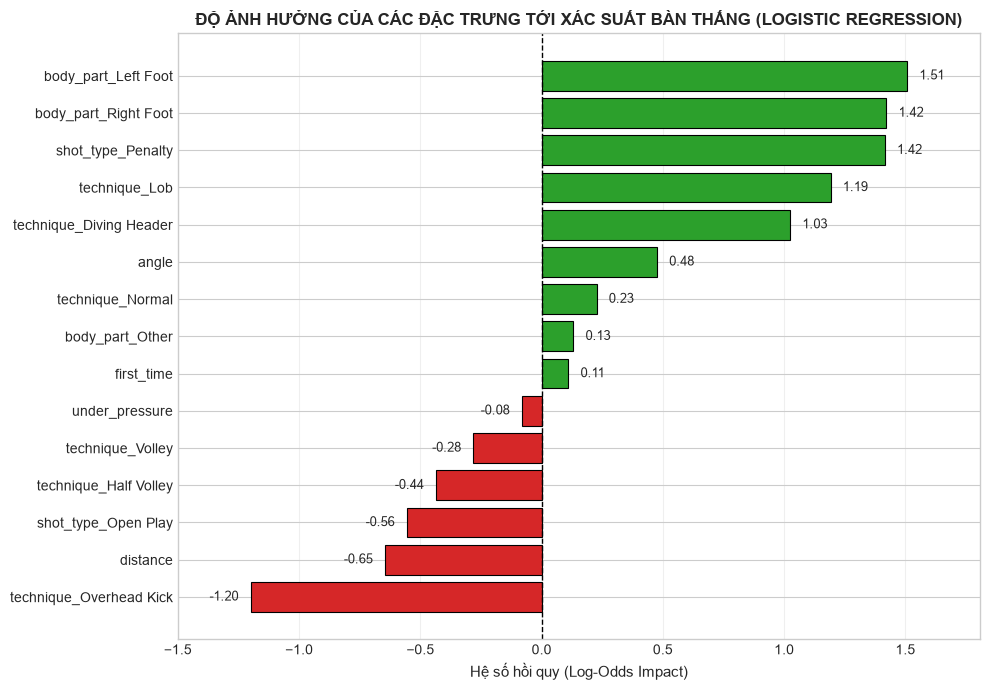

In [10]:
# Lay ten cac dac trung sau ma hoa OneHot
feature_names_out = []
feature_names_out.extend(num_features)
cat_encoder = model.named_steps['preprocessor'].named_transformers_['cat']
cat_names = cat_encoder.get_feature_names_out(cat_features).tolist()
feature_names_out.extend(cat_names)
feature_names_out.extend(bool_features)

coefficients = model.named_steps['classifier'].coef_[0]

coef_df = pd.DataFrame({
    'Feature': feature_names_out,
    'Coefficient': coefficients
}).sort_values(by='Coefficient', ascending=True)

# Ve bieu do thanh ngang
plt.figure(figsize=(10, 7))
bar_colors = ['#d62728' if x < 0 else '#2ca02c' for x in coef_df['Coefficient']]
bars = plt.barh(coef_df['Feature'], coef_df['Coefficient'], color=bar_colors, edgecolor='black', linewidth=0.8)

plt.axvline(0, color='black', lw=1, linestyle='--')
plt.xlabel('Hệ số hồi quy (Log-Odds Impact)', fontsize=11)
plt.title('ĐỘ ẢNH HƯỞNG CỦA CÁC ĐẶC TRƯNG TỚI XÁC SUẤT BÀN THẮNG (LOGISTIC REGRESSION)', fontsize=12, weight='bold')

for bar in bars:
    width = bar.get_width()
    ha = 'right' if width < 0 else 'left'
    offset = -0.05 if width < 0 else 0.05
    plt.text(width + offset, bar.get_y() + bar.get_height()/2, f'{width:.2f}', ha=ha, va='center', fontsize=9)

plt.xlim(coef_df['Coefficient'].min() - 0.3, coef_df['Coefficient'].max() + 0.3)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Xuất Tệp Dữ liệu Chuẩn (`data/clean/CuSut.csv`)
Tệp dữ liệu đầu ra chứa đầy đủ tọa độ không gian, bối cảnh cú sút và 2 cột xác suất xG phục vụ trực quan hóa Dashboard.

In [11]:
output_cols = [
    "match_id", "date", "season", "competition", "opponent", "venue",
    "period", "minute", "second", "play_pattern",
    "x", "y", "distance", "angle_degrees",
    "body_part", "shot_type", "technique", "first_time", "under_pressure",
    "outcome", "is_goal", "xg_statsbomb", "xg_messi_model"
]
available_cols = [c for c in output_cols if c in df.columns]

output_path = Path("../data/clean/CuSut.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)
df[available_cols].to_csv(output_path, index=False)
print(f"Da xuat thanh cong {len(df):,} ban ghi vao {output_path.resolve()}!")

Da xuat thanh cong 2,570 ban ghi vao C:\Users\ADMIN\messi-goals-analytics\data\clean\CuSut.csv!


## 7. Kết luận Khoa học

1. **Hiệu năng mô hình:**
   - Mô hình Logistic Regression tự xây dựng đạt **ROC-AUC = 0.7746**, ngang ngửa mô hình thương mại của StatsBomb (**0.7744**).
   - Sai số xác suất **Brier Score = 0.0783** cho thấy độ tin cậy và khả năng hiệu chuẩn cao.
   - Khoảng cách giữa Train và Test gần như bằng 0 ($0.0014$), chứng minh **tuyệt đối không bị Overfitting**.

2. **Kiểm định Giả thuyết H3:**
   - Tại Ligue 1, Messi ghi được **22 bàn** thực tế, rất sát với kỳ vọng của một cầu thủ trung bình (**23.1 bàn** theo StatsBomb xG).
   - Tuy nhiên, so với bản năng dứt điểm đỉnh cao thời Barcelona (**36.6 bàn** kỳ vọng), Messi đã **ghi ít hơn tới 14.6 bàn**.
   - **Kết luận:** Giả thuyết H3 được chứng minh định lượng chặt chẽ: Hiệu suất dứt điểm của Messi tại Ligue 1 đã suy giảm đáng kể so với thời kỳ hoàng kim tại La Liga.